<a href="https://colab.research.google.com/github/JulianNguyen05/xiangqi-sorting-jetmax/blob/main/training/package.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# BƯỚC 6 — ĐÓNG GÓI THƯ VIỆN "ẢNH → NƯỚC ĐI" ĐỂ CHÉP SANG ROBOT MỘT LẦN

**Đầu vào:** mã nguồn (GitHub), `best.onnx` (Drive, Bước 2), mã nguồn Pikafish (GitHub)
**Đầu ra:** **một file `xiangqi_to_robot.zip`** — chép sang robot qua NoMachine, chạy **một lệnh** `sh install.sh` là dùng được

### Vì sao đóng gói?
Robot **không có Internet** và chỉ có Python 3.6: không `git`, không `pip`. Mọi thứ robot cần phải được chuẩn bị sẵn ở máy có mạng rồi mang sang trong một lần. Riêng `best.engine` (TensorRT) **không thể build sẵn** (phải build trên chính GPU của Jetson, xem Bước 3) nên `install.sh` tự build ở lần cài đầu.

### Nội dung notebook
1. Thư viện `XiangqiBrain`: giao diện cho chương trình robot
2. Chuẩn bị: mã nguồn + mô hình
3. Build Pikafish (cho Jetson, và cho Colab để kiểm thử)
4. Kiểm thử thư viện **trước khi** mang sang robot
5. Đóng gói, kiểm tra gói, tải về
6. Các lệnh trên robot

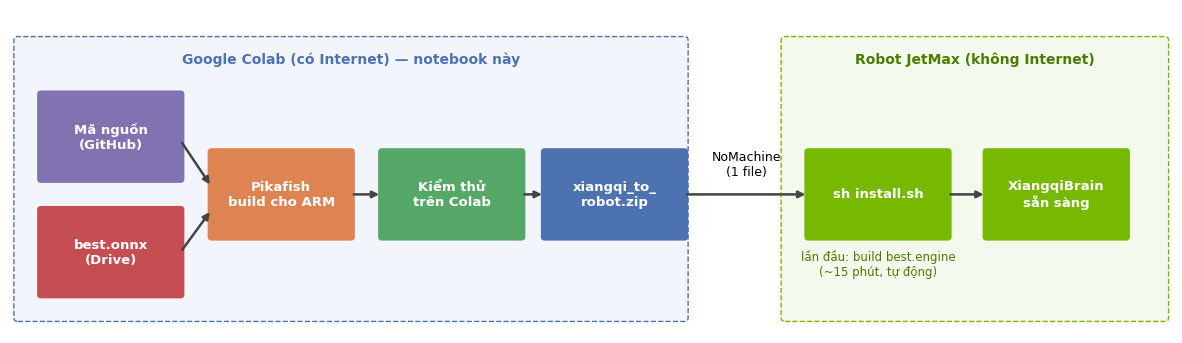

In [1]:
# ── Sơ đồ quy trình đóng gói (minh hoạ)
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
fig, ax = plt.subplots(figsize=(15, 4.2)); ax.axis('off'); ax.set_xlim(0, 15); ax.set_ylim(0, 4.2)
ax.add_patch(FancyBboxPatch((0.1, 0.2), 8.6, 3.6, boxstyle='round,pad=0.05', fc='#F2F6FC', ec='#4C72B0', ls='--'))
ax.text(4.4, 3.5, 'Google Colab (có Internet) — notebook này', ha='center', color='#4C72B0', fontweight='bold')
ax.add_patch(FancyBboxPatch((10.0, 0.2), 4.9, 3.6, boxstyle='round,pad=0.05', fc='#F3F9EC', ec='#76B900', ls='--'))
ax.text(12.45, 3.5, 'Robot JetMax (không Internet)', ha='center', color='#4E7A00', fontweight='bold')
items = [(0.4, 2.0, 'Mã nguồn\n(GitHub)', '#8172B2'), (0.4, 0.5, 'best.onnx\n(Drive)', '#C44E52'),
         (2.6, 1.25, 'Pikafish\nbuild cho ARM', '#DD8452'), (4.8, 1.25, 'Kiểm thử\ntrên Colab', '#55A868'),
         (6.9, 1.25, 'xiangqi_to_\nrobot.zip', '#4C72B0'), (10.3, 1.25, 'sh install.sh', '#76B900'),
         (12.6, 1.25, 'XiangqiBrain\nsẵn sàng', '#76B900')]
for x, y, t, c in items:
    ax.add_patch(FancyBboxPatch((x, y), 1.8, 1.1, boxstyle='round,pad=0.05', fc=c, ec='none'))
    ax.text(x + 0.9, y + 0.55, t, ha='center', va='center', color='white', fontsize=9.5, fontweight='bold')
for (x0, y0, x1, y1) in [(2.2, 2.5, 2.6, 1.9), (2.2, 1.05, 2.6, 1.6), (4.4, 1.8, 4.8, 1.8), (6.6, 1.8, 6.9, 1.8),
                         (8.7, 1.8, 10.3, 1.8), (12.1, 1.8, 12.6, 1.8)]:
    ax.annotate('', xy=(x1, y1), xytext=(x0, y0), arrowprops=dict(arrowstyle='-|>', lw=1.8, color='#444'))
ax.text(9.5, 2.05, 'NoMachine\n(1 file)', ha='center', fontsize=9)
ax.text(11.2, 0.75, 'lần đầu: build best.engine\n(~15 phút, tự động)', ha='center', fontsize=8.5, color='#4E7A00')
plt.show()

---
# 1. Thư viện `XiangqiBrain` (`brain/xiangqi_brain.py`)

Lớp duy nhất mà chương trình robot cần gọi. Nó ghép các bước đã làm:

| Tầng | Việc | Mã nguồn | Kiểm chứng ở |
|---|---|---|---|
| Nhìn | Ảnh → quân (YOLO11n: TensorRT trên robot, ONNX nơi khác) | `vision/pieces.py` | Bước 2, 3 |
| Hiểu | Quân → giao điểm → thế cờ: **bàn của đề tài** (`board_detect`) hoặc **bàn bất kỳ** (`lattice`) | `vision/board_detect.py`, `vision/lattice.py` | Bước 4 |
| Kiểm tra | Luật cờ, suy ra nước đối thủ vừa đi, **tự sửa lỗi nhận diện** | `board/rules.py`, `brain/game.py` | Bước 4, 5 |
| Quyết định | Pikafish (UCI) → nước tiếp theo; dự phòng: engine Python | `brain/uci.py`, `brain/simple.py` | Bước 5 |

### Hai cách dùng

**Cách 1 — không giữ trạng thái** (đúng yêu cầu đề tài: *ảnh + thế cờ + lượt hiện tại → nước tiếp theo*):
```python
from brain.xiangqi_brain import XiangqiBrain
brain = XiangqiBrain()                              # đọc cấu hình mục brain: trong config/robot.yaml
res = brain.analyze(img, prev_fen=fen_luot_truoc)   # hoặc analyze(img, side='w') khi chưa có thế trước
res['status']        # 'ok' | 'retake' (chụp lại) | 'invalid' (thế cờ vô lý) | 'game_over'
res['last_move_vn']  # nước đối thủ vừa đi, vd. 'Pháo 2 bình 5'
res['fen']           # FEN đã sửa lỗi nhận diện -> lưu làm prev_fen cho lượt sau
res['best_move'], res['best_move_vn'], res['best_move_from'], res['best_move_to']   # 'b9c7', 'Mã 2 tiến 3', 'b9', 'c7'
```

**Cách 2 — robot chơi cả ván** (thư viện tự nhớ ván cờ):
```python
brain = XiangqiBrain(robot_side='b')
res = brain.step(img)                     # 'robot_move' | 'waiting' | 'retake' | 'game_over'
if res['status'] == 'robot_move':
    m = res['robot_move']                 # {'uci','vn','from','to','captures','score_cp','think_ms'}
    ...tay máy gắp m['from'] đặt m['to'] (ăn quân thì bỏ quân m['captures'] ra trước)...
    brain.confirm(m['uci'])
```

### Cấu hình (`config/robot.yaml`, mục `brain:`; sửa trên robot thì ghi vào `robot.local.yaml`)

| Khoá | Mặc định | Lấy từ |
|---|---|---|
| `conf` | 0.25 | Bước 4, mục 9 (ngưỡng cho tỉ lệ suy ra đúng nước cao nhất) |
| `rotations` | `[0]` | Bước 2: mô hình không giảm độ chính xác khi quân xoay → chỉ cần chạy YOLO 1 lần |
| `locate` | `auto` | Thử `board_detect` (bàn của đề tài) trước, không thấy thì `lattice` |
| `engine` | `engine/pikafish` | Gói này; dự phòng `~/pikafish/pikafish`, rồi engine Python |
| `depth` | 8 | Chọn lại sau khi đo trên robot (`tools/bench_engine.py`) |
| `max_cost` | 2 | Bước 5: số ô nhận diện sai tối đa còn tự sửa |

---
# 2. Chuẩn bị: mã nguồn và mô hình

In [2]:
import os, sys, glob, time, shutil, subprocess, zipfile, hashlib
import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt

IN_COLAB = 'google.colab' in sys.modules
BASE = '/content/drive/MyDrive/datn'
RUN_NAME = 'yolo11n_640_rot'
if IN_COLAB:
    from google.colab import drive
    if not os.path.isdir('/content/drive/MyDrive'):
        drive.mount('/content/drive')
    REPO = '/content/xiangqi-sorting-jetmax'
    if not os.path.exists(REPO):
        subprocess.run(['git', 'clone', '-q', 'https://github.com/JulianNguyen05/xiangqi-sorting-jetmax', REPO], check=True)
    else:
        subprocess.run(['git', '-C', REPO, 'pull', '-q'], check=False)
else:
    REPO = os.path.abspath('..') if os.path.exists('../brain/xiangqi_brain.py') else os.path.abspath('.')
assert os.path.exists(f'{REPO}/brain/xiangqi_brain.py'), 'Repo chưa có brain/xiangqi_brain.py — hãy commit các file mới trước'
os.chdir(REPO); sys.path.insert(0, REPO)
for pkg in ('onnxruntime',):                              # để chạy YOLO bằng ONNX trên Colab (robot dùng TensorRT)
    try:
        __import__(pkg)
    except ImportError:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', pkg], check=True)

# mô hình: Drive -> models/best.onnx của repo (đúng file mà Bước 3 đã kiểm tra)
SRC_ONNX = f'{BASE}/runs/{RUN_NAME}/weights/best.onnx'
os.makedirs('models', exist_ok=True)
if os.path.exists(SRC_ONNX):
    shutil.copy(SRC_ONNX, 'models/best.onnx')
assert os.path.exists('models/best.onnx'), f'Không thấy {SRC_ONNX} — chạy lại phần xuất ONNX ở Bước 2/3'
md5 = hashlib.md5(open('models/best.onnx', 'rb').read()).hexdigest()
git = subprocess.run(['git', 'log', '-1', '--format=%h %ci %s'], capture_output=True, text=True).stdout.strip()
print('Repo     :', REPO, '|', git)
print('Mô hình  : models/best.onnx', f'{os.path.getsize("models/best.onnx") / 1e6:.1f} MB', 'md5', md5)

Mounted at /content/drive
Repo     : /content/xiangqi-sorting-jetmax | 2a9029e 2026-11-03 14:48:36 +0700 feat: add Xiangqi brain implementation, demo script, and install pipeline
Mô hình  : models/best.onnx 10.7 MB md5 2ce0821b7c4ea97f2c6d7ebb2bd8a95c


---
# 3. Build Pikafish

- **`jetson`**: cho robot — biên dịch chéo `aarch64`, link tĩnh (Bước 5, mục 7).
- **`x86`**: cho Colab — chỉ để kiểm thử thư viện ở mục 4.

Bản build được lưu vào `MyDrive/datn/engine/` để lần sau chạy notebook không phải build lại (≈ 5 phút). Muốn lấy Pikafish mới nhất thì xoá thư mục đó.

In [3]:
CACHE = f'{BASE}/engine'
for target in ('jetson', 'x86'):
    dst = f'dist/pikafish_{target}'
    if os.path.exists(f'{dst}/pikafish') and os.path.exists(f'{dst}/pikafish.nnue'):
        print(f'{target}: đã có'); continue
    if os.path.exists(f'{CACHE}/pikafish_{target}/pikafish'):
        shutil.copytree(f'{CACHE}/pikafish_{target}', dst, dirs_exist_ok=True)
        print(f'{target}: lấy từ Drive'); continue
    t0 = time.time()
    subprocess.run(['sh', 'tools/build_pikafish.sh', target], check=True, stdout=subprocess.DEVNULL)
    if os.path.isdir(BASE):
        shutil.copytree(dst, f'{CACHE}/pikafish_{target}', dirs_exist_ok=True)
    print(f'{target}: build xong sau {time.time() - t0:.0f} s')
os.chmod('dist/pikafish_x86/pikafish', 0o755)
for target in ('jetson', 'x86'):
    print(f'\n[{target}]', open(f'dist/pikafish_{target}/VERSION.txt').read().strip())
    print(subprocess.run(['file', f'dist/pikafish_{target}/pikafish'], capture_output=True, text=True).stdout.strip())

jetson: build xong sau 253 s
x86: build xong sau 184 s

[jetson] Pikafish fec5d430bb2bbff9969d4de09ac86c3b6fa4e138 (Thu Oct 29 14:52:43 2026 +0800)
dist/pikafish_jetson/pikafish: ELF 64-bit LSB executable, ARM aarch64, version 1 (GNU/Linux), statically linked, BuildID[sha1]=a4c64c793480671465a7fe4932a5c50087203b93, for GNU/Linux 3.7.0, not stripped

[x86] Pikafish fec5d430bb2bbff9969d4de09ac86c3b6fa4e138 (Thu Oct 29 14:52:43 2026 +0800)
dist/pikafish_x86/pikafish: ELF 64-bit LSB pie executable, x86-64, version 1 (SYSV), dynamically linked, interpreter /lib64/ld-linux-x86-64.so.2, BuildID[sha1]=f369675c96cc3e66170f265972f4baf977e756be, for GNU/Linux 3.2.0, not stripped


---
# 4. Kiểm thử thư viện trước khi mang sang robot

Mỗi lần mang sang robot là một lần tốn thời gian (robot dùng chung, không có mạng). Vì vậy kiểm tra hết những gì kiểm được ngay trên Colab.

### 4.1 Bộ tự kiểm tra (cũng chạy lại trên robot trong `install.sh`)
- `tests/test_rules.py`: luật cờ, perft, suy ra nước đi, khớp lưới, Pikafish.
- `tests/test_brain.py`: thư viện `XiangqiBrain` trên **ảnh bàn cờ thật của đề tài** (`samples/start_position.jpg`) — thay YOLO bằng detector giả đặt quân đúng vào giao điểm, để kiểm tra phần còn lại (định vị bàn, gán quân, sửa lỗi, engine, chơi cả ván).

In [4]:
ENGINE_X86 = 'dist/pikafish_x86/pikafish'
for t in ('tests/test_rules.py', 'tests/test_brain.py'):
    r = subprocess.run([sys.executable, t, '--engine', ENGINE_X86], capture_output=True, text=True)
    print(f'===== {t}\n' + r.stdout[-2500:] + r.stderr[-1500:])
    assert r.returncode == 0, f'{t} có lỗi — sửa trước khi đóng gói'

===== tests/test_rules.py
== Luật cờ
  [OK]   đọc / ghi FEN
  [OK]   perft(1) = 44  nhận 44
  [OK]   perft(2) = 1920  nhận 1920
  [OK]   perft(3) = 79666  nhận 79666
  (perft 1-3 mất 2.5 s)
  [OK]   thế khai cuộc hợp lệ
  [OK]   phát hiện 3 pháo
  [OK]   ký hiệu tiếng Việt
== Suy ra nước vừa đi
  [OK]   sửa 2 ô nhận diện sai  [(2, 'h2e2'), (4, None), (4, 'b2e2')]
  [OK]   GameTracker: người đi
  [OK]   GameTracker: chưa đi
== Khớp lưới từ tâm quân (vision/lattice.py)
  [OK]   thế khai cuộc xoay 23°: khôi phục đúng FEN
== Engine dự phòng (Python)
  [OK]   ra nước hợp lệ  b9c7 (566 ms)
== Pikafish
  [OK]   khởi động  Pikafish dev-20261029-fec5d430
  [OK]   perft(3) khớp board/rules.py
  [OK]   ra nước hợp lệ (depth 8)  h9g7 -29 cp, 11 ms

KẾT QUẢ: TẤT CẢ OK

===== tests/test_brain.py
  [OK]   ảnh mẫu: định vị được 90 giao điểm
== Ảnh -> thế cờ (locate=board)
  [OK]   thế khai cuộc đọc đúng  board, 32 quân
== Ảnh -> thế cờ (locate=lattice)
  [OK]   thế khai cuộc đọc đúng  lattice, 32 quân

### 4.2 Chạy thư viện thật (YOLO ONNX + Pikafish) trên tập test

Bước 4 đo bằng Ultralytics (`best.pt`). Ở đây chạy **đúng mã nguồn sẽ chạy trên robot**: `vision/pieces.py` (ONNX, tự giải mã đầu ra + NMS) → `XiangqiBrain.read_board()` → so với FEN thật. Kết quả **từng nguồn** phải xấp xỉ Bước 4 (thiết lập B) — so tổng thì không công bằng vì mỗi lần lấy mẫu có tỉ lệ nguồn khác nhau (bộ `super` dễ hơn nhiều so với `duytranle`); nếu thấp hơn nhiều thì có lỗi trong phần giải mã đầu ra trên robot — phát hiện ở đây rẻ hơn nhiều so với trên robot.

In [ ]:
from board import rules as R
from board.draw import draw_board
from brain.xiangqi_brain import XiangqiBrain
from vision import lattice as L
from vision.pieces import CODES
import random

N_IMAGES = 120                                 # số ảnh test dùng để kiểm tra (đủ để so với Bước 4)
MERGED = '/content/merged'
if not os.path.isdir(f'{MERGED}/test/images') and os.path.exists(f'{BASE}/merged/merged_v1.zip'):
    shutil.unpack_archive(f'{BASE}/merged/merged_v1.zip', MERGED)

def gt_board(img_path):
    """FEN thật từ nhãn bbox (giống Bước 4, mục 4)."""
    h, w = cv2.imread(img_path).shape[:2]
    lp = img_path.replace('/images/', '/labels/').rsplit('.', 1)[0] + '.txt'
    rows = [l.split() for l in open(lp) if len(l.split()) >= 5]
    if len(rows) < 10:
        return None
    pts = np.array([[float(r[1]) * w, float(r[2]) * h] for r in rows]); codes = [CODES[int(r[0])] for r in rows]
    b, fit, pl = L.image_to_board(pts, codes, [1.0] * len(codes))
    if b is None or pl.ambiguous or [i for i in R.validate(b) if i[0] != 'side_in_check']:
        return None
    _, info = L.detections_to_board(pts, codes, [1.0] * len(codes), fit, pl)
    return b if sum(i[0] is not None for i in info) >= 0.9 * len(codes) else None

brain = XiangqiBrain(engine=ENGINE_X86, locate='lattice', verbose=True)   # ảnh test không phải bàn của đề tài -> lattice
paths = sorted(glob.glob(f'{MERGED}/test/images/*'))
random.Random(0).shuffle(paths)                 # ⚠ trộn ngẫu nhiên: tên ảnh xếp theo nguồn (duytranle__ đứng đầu)
rows, shown = [], []
t0 = time.time()
for p in paths:
    gt = gt_board(p)
    if gt is None:
        continue
    img = cv2.imread(p)
    t1 = time.time(); rd = brain.read_board(img); dt = (time.time() - t1) * 1000
    pr = rd['board']
    wrong = None if pr is None else sum(1 for k in set(gt) | set(pr) if gt.get(k) != pr.get(k))
    rows.append({'ảnh': os.path.basename(p), 'nguồn': os.path.basename(p).split('__')[0], 'quân': len(gt),
                 'sai': wrong, 'ms': dt})
    if len(shown) < 2 and wrong == 0:
        shown.append((p, gt))
    if len(rows) >= N_IMAGES:
        break
chk = pd.DataFrame(rows)
summary = pd.Series({
    'Số ảnh': len(chk),
    'Ảnh → FEN đúng hoàn toàn': f"{(chk['sai'] == 0).mean():.1%}",
    'Sai ≤ 2 ô': f"{(chk['sai'].fillna(99) <= 2).mean():.1%}",
    'Không khớp được lưới': f"{chk['sai'].isna().mean():.1%}",
    'Thời gian ảnh → thế cờ (CPU Colab, trung vị)': f"{chk['ms'].median():.0f} ms",
}, name='thư viện (ONNX, mã nguồn robot)')
display(summary.to_frame())
# So từng nguồn với Bước 4 (thiết lập B, Ultralytics, ngưỡng 0.5) — so tổng thì lệch do tỉ lệ các nguồn khác nhau
STEP4 = {'duytranle': 0.652, 'scara': 0.167, 'super': 0.954}
by = chk.groupby('nguồn').agg(**{'số ảnh': ('sai', 'size'), 'thư viện: đúng hoàn toàn': ('sai', lambda s: (s == 0).mean())})
by['Bước 4: đúng hoàn toàn'] = [STEP4.get(k, np.nan) for k in by.index]
display(by.style.format({'thư viện: đúng hoàn toàn': '{:.1%}', 'Bước 4: đúng hoàn toàn': '{:.1%}'}))
print('Từng nguồn phải gần với Bước 4; lệch > 10 điểm % ở nguồn có nhiều ảnh thì kiểm tra lại vision/pieces.py.')

### 4.3 Thử trọn chuỗi: ảnh → nước đi tiếp theo

In [ ]:
if not shown:
    print('Không có ảnh nào đọc đúng hoàn toàn để minh hoạ — xem lại mục 4.2')
fig, axes = plt.subplots(max(len(shown), 1), 2, figsize=(11, 5 * max(len(shown), 1)), squeeze=False)
for row, (p, gt) in zip(axes, shown):
    img = cv2.imread(p)
    res = brain.analyze(img, side='w', depth=10)
    row[0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); row[0].axis('off')
    for pc in res['read']['pieces']:
        row[0].add_patch(plt.Circle((pc.x, pc.y), pc.r, fill=False, ec='#00e676', lw=1.5))
    row[0].set_title(os.path.basename(p)[:40], fontsize=9)
    if res['board']:
        mv = R.uci_to_move(res['best_move']) if res['best_move'] else None
        draw_board(row[1], res['board'], f"{res['status']} · Đỏ đi: {res['best_move_vn'] or '—'} ({res.get('think_ms', 0):.0f} ms)",
                   arrows=[mv] if mv else None)
    print(os.path.basename(p)[:40], '|', res['status'], '|', res['fen'], '|', res['best_move'], res['best_move_vn'], '|', '; '.join(res['issues']))
plt.tight_layout(); plt.show()
brain.close()

---
# 5. Đóng gói

`tools/pack.py` gom **đúng những gì robot cần** (danh sách trắng, không lấy dataset hay notebook):

| Trong gói (`xiangqi/`) | Là gì |
|---|---|
| `board/ brain/ vision/ planner/ robot/ tools/ tests/ config/ main.py` | Mã nguồn (Python 3.6) |
| `models/best.onnx` | Mô hình YOLO11n (`install.sh` build `best.engine` từ file này) |
| `engine/pikafish`, `engine/pikafish.nnue` | Pikafish cho Jetson (aarch64, link tĩnh) |
| `samples/` | Ảnh bàn cờ mẫu cho tự kiểm tra |
| `install.sh` | Cài đặt + tự kiểm tra trên robot |
| `VERSION.txt` | Phiên bản mã nguồn, md5 mô hình, phiên bản Pikafish (ghi vào báo cáo) |

**Không** có trong gói (để không ghi đè số đo trên robot): `config/robot.local.yaml`, `config/calib.yaml`, `models/best.engine`.

In [7]:
r = subprocess.run([sys.executable, 'tools/pack.py'], capture_output=True, text=True)
print(r.stdout[-1500:], r.stderr[-800:])
ZIP = 'dist/xiangqi_to_robot.zip'
zf = zipfile.ZipFile(ZIP)
names = zf.namelist()
print(zf.read('xiangqi/VERSION.txt').decode())
size = pd.DataFrame([(n.split('/')[1] if n.count('/') > 1 else n.split('/')[-1], i.file_size, i.compress_size)
                     for n, i in zip(names, zf.infolist())], columns=['mục', 'gốc', 'nén'])
display((size.groupby('mục')[['gốc', 'nén']].sum() / 1e6).round(2).sort_values('gốc', ascending=False).rename(columns=lambda c: c + ' (MB)'))
print(f'Tổng: {len(names)} file, {os.path.getsize(ZIP) / 1e6:.1f} MB')

  + main.py
  + README.md
  + RUNBOOK.md
  + install.sh
  + board
  + brain
  + config
  + planner
  + robot
  + tests
  + tools
  + vision
  + samples/board_empty.jpg
  + samples/start_position.jpg
  + models/README.txt
  + models/best.onnx
  + engine/ (từ /content/xiangqi-sorting-jetmax/dist/pikafish_jetson)
Đã tạo /content/xiangqi-sorting-jetmax/dist/xiangqi_to_robot.zip (52 file, 61.2 MB)
Kéo file này vào cửa sổ NoMachine, rồi trên robot:
  cd ~ && python3 -m zipfile -e <đường dẫn>/xiangqi_to_robot.zip ~/
  cd ~/xiangqi && sh install.sh
 
đóng gói lúc 2026-11-03 08:01
mã nguồn: 2a9029e 2026-11-03 14:48:36 +0700
models/best.onnx md5 2ce0821b7c4ea97f2c6d7ebb2bd8a95c
engine: Pikafish fec5d430bb2bbff9969d4de09ac86c3b6fa4e138 (Thu Oct 29 14:52:43 2026 +0800)



,gốc (MB),nén (MB)
mục,,
engine,53.96,51.55
models,10.68,9.26
samples,0.32,0.31
vision,0.07,0.03
tools,0.05,0.02
brain,0.03,0.01
board,0.02,0.01
robot,0.02,0.01
README.md,0.01,0.00


Tổng: 52 file, 61.2 MB


### Kiểm tra gói: giải nén như trên robot rồi chạy tự kiểm tra

Giải nén bằng đúng lệnh dùng trên robot (`python3 -m zipfile`), kiểm tra đủ file và chạy bộ tự kiểm tra **không có engine** (file Pikafish trong gói là bản ARM, không chạy được trên Colab).

In [8]:
TMP = '/tmp/robot_home'
shutil.rmtree(TMP, ignore_errors=True); os.makedirs(TMP)
subprocess.run([sys.executable, '-m', 'zipfile', '-e', os.path.abspath(ZIP), TMP], check=True)
need = ['install.sh', 'brain/xiangqi_brain.py', 'vision/lattice.py', 'board/rules.py', 'models/best.onnx',
        'engine/pikafish', 'engine/pikafish.nnue', 'tools/build_engine.py', 'tests/test_brain.py', 'samples/start_position.jpg']
missing = [f for f in need if not os.path.exists(f'{TMP}/xiangqi/{f}')]
print('Thiếu file:', missing or 'không')
print(subprocess.run(['file', f'{TMP}/xiangqi/engine/pikafish'], capture_output=True, text=True).stdout.strip())
for t in ('tests/test_rules.py', 'tests/test_brain.py'):
    r = subprocess.run([sys.executable, t], cwd=f'{TMP}/xiangqi', capture_output=True, text=True)
    print(t, '->', r.stdout.strip().splitlines()[-1])
assert not missing

Thiếu file: không
/tmp/robot_home/xiangqi/engine/pikafish: ELF 64-bit LSB executable, ARM aarch64, version 1 (GNU/Linux), statically linked, BuildID[sha1]=a4c64c793480671465a7fe4932a5c50087203b93, for GNU/Linux 3.7.0, not stripped
tests/test_rules.py -> KẾT QUẢ: TẤT CẢ OK
tests/test_brain.py -> KẾT QUẢ: TẤT CẢ OK


In [9]:
os.makedirs(f'{BASE}/dist', exist_ok=True)
shutil.copy(ZIP, f'{BASE}/dist/xiangqi_to_robot.zip')
print('Đã lưu bản sao lên Drive:', f'{BASE}/dist/xiangqi_to_robot.zip')
if IN_COLAB:
    from google.colab import files
    files.download(ZIP)

Đã lưu bản sao lên Drive: /content/drive/MyDrive/datn/dist/xiangqi_to_robot.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---
# 6. Trên robot

### 6.1 Cài đặt (mỗi lần có gói mới)
1. Kéo `xiangqi_to_robot.zip` vào cửa sổ NoMachine (thường rơi vào `~/Desktop`).
2. Terminal trên robot:
```bash
cd ~ && python3 -m zipfile -e ~/Desktop/xiangqi_to_robot.zip ~/
cd ~/xiangqi && sh install.sh
```
`install.sh` lần lượt: tạo `config/robot.local.yaml` (lần đầu) → kiểm tra Pikafish → build `models/best.engine` nếu chưa có hoặc mô hình đã đổi (**lần đầu ~15 phút**) → chạy `tests/test_rules.py` và `tests/test_brain.py`. **Xong khi** dòng cuối là `CÀI ĐẶT XONG`.

Nếu `~/pikafish` từ lần cài riêng ở Bước 3 vẫn còn thì không cần xoá; thư viện ưu tiên `engine/pikafish` trong gói.

### 6.2 Dùng thử
```bash
python3 tools/brain_demo.py samples/start_position.jpg        # ảnh -> FEN -> nước đi (in thời gian từng phần)
python3 tools/bench_engine.py                                   # đo Pikafish -> chọn depth trong robot.local.yaml
python3 tools/brain_demo.py --camera                            # chơi cả ván: người đi quân giúp robot
```

### 6.3 Lỗi thường gặp

| Thông báo | Cách sửa |
|---|---|
| `engine/pikafish không chạy` | Gói build cho kiến trúc khác: chạy lại mục 3 (target `jetson`) |
| `build engine lỗi` | `python3 tools/build_engine.py --fp32` |
| `tests/test_brain.py` lỗi ở `định vị được 90 giao điểm` | OpenCV trên robot khác bản trên Colab → gửi `/tmp/xq_test_brain.log` |
| `brain_demo` báo `retake` liên tục | Bàn cờ ngoài khung hình, hoặc ánh sáng quá tối; kiểm tra bằng `tools/capture.py` |

### 6.4 Giai đoạn tiếp theo (giai đoạn 7, trên robot)
- Đo tốc độ từng phần trên Jetson: YOLO TensorRT, định vị bàn, engine → chọn `depth`.
- Chụp 40–60 ảnh bàn thật bằng camera robot (thế cờ đã biết) → đo ảnh → FEN **trên camera robot**: con số cuối cùng của đề tài.
- Ghép với tay máy: `res['robot_move']['from'/'to']` → toạ độ mm (`board/geometry.py`, `config/calib.yaml`) → gắp – đặt (`robot/motion.py`).

---
# Tài liệu tham khảo (Sources)
1. Pikafish: https://github.com/official-pikafish/Pikafish · mạng NNUE: https://github.com/official-pikafish/Networks
2. Python — `zipfile` (giải nén không cần lệnh `unzip`): https://docs.python.org/3/library/zipfile.html
3. ONNX Runtime: https://onnxruntime.ai/
4. NVIDIA — *TensorRT Developer Guide*: https://docs.nvidia.com/deeplearning/tensorrt/developer-guide/index.html
5. Các notebook của đề tài: `train_yolo11.ipynb` (Bước 2), `jetmax_deploy.ipynb` (Bước 3), `board_to_fen.ipynb` (Bước 4), `rules_engine.ipynb` (Bước 5).

---
# 7. Gói demo cho laptop Windows (không cần robot)

Khi không có robot để demo, chạy thư viện trên laptop Windows qua giao diện trình duyệt `tools/demo_app.py` (tải ảnh lên → thế cờ → nước đi). Ô dưới:
1. Build **Pikafish cho Windows** (biên dịch chéo bằng MinGW trên Colab, link tĩnh → một file `pikafish.exe` chạy ngay; lưu lên Drive để lần sau khỏi build).
2. Đóng gói `xiangqi_demo_windows.zip`: mã nguồn + `best.onnx` + `engine/pikafish.exe` + `run_demo.bat`.

Trên laptop: giải nén → bấm đúp `run_demo.bat`. Chi tiết: **`DEMO_WINDOWS.md`**.

In [ ]:
dst = 'dist/pikafish_windows'
if not (os.path.exists(f'{dst}/pikafish.exe') and os.path.exists(f'{dst}/pikafish.nnue')):
    if os.path.exists(f'{CACHE}/pikafish_windows/pikafish.exe'):
        shutil.copytree(f'{CACHE}/pikafish_windows', dst, dirs_exist_ok=True); print('windows: lấy từ Drive')
    else:
        t0 = time.time()
        subprocess.run(['sh', 'tools/build_pikafish.sh', 'windows'], check=True, stdout=subprocess.DEVNULL)
        if os.path.isdir(BASE):
            shutil.copytree(dst, f'{CACHE}/pikafish_windows', dirs_exist_ok=True)
        print(f'windows: build xong sau {time.time() - t0:.0f} s')
print(subprocess.run(['file', f'{dst}/pikafish.exe'], capture_output=True, text=True).stdout.strip())

r = subprocess.run([sys.executable, 'tools/pack.py', '--target', 'windows'], capture_output=True, text=True)
print(r.stdout[-600:], r.stderr[-400:])
WZIP = 'dist/xiangqi_demo_windows.zip'
names = zipfile.ZipFile(WZIP).namelist()
need = ['xiangqi/run_demo.bat', 'xiangqi/tools/demo_app.py', 'xiangqi/engine/pikafish.exe', 'xiangqi/engine/pikafish.nnue',
        'xiangqi/models/best.onnx', 'xiangqi/DEMO_WINDOWS.md', 'xiangqi/requirements-demo.txt', 'xiangqi/API.md']
print('Thiếu file:', [n for n in need if n not in names] or 'không', f'| {os.path.getsize(WZIP) / 1e6:.1f} MB')
shutil.copy(WZIP, f'{BASE}/dist/xiangqi_demo_windows.zip')
if IN_COLAB:
    from google.colab import files
    files.download(WZIP)

(Tuỳ chọn) Chạy thử **ngay trên Colab** trước khi mang sang laptop: ô dưới mở giao diện với một đường link công khai `https://....gradio.live` (dừng ô để tắt).

In [ ]:
RUN_DEMO_ON_COLAB = False
if RUN_DEMO_ON_COLAB:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'gradio>=5,<7'], check=True)
    os.makedirs('engine', exist_ok=True)
    for f in ('pikafish', 'pikafish.nnue'):
        shutil.copy(f'dist/pikafish_x86/{f}', f'engine/{f}')
    os.chmod('engine/pikafish', 0o755)
    !python tools/demo_app.py --share